# 第14章：聚类目标与自然分组

**学生实验｜全书深化稿**

## 背景与数据
一维Lloyd例子、人工双月数据、已有标签隐藏后的标准数据分析。

## 本次要回答的问题
核对局部稳定解，比较K均值/层次/DBSCAN及不同指标。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 14: K-means updates, non-convex shapes and stability."""
import numpy as np
from sklearn.cluster import KMeans,DBSCAN,AgglomerativeClustering
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score,silhouette_score
from common import *

def run():
    x=np.array([0.,1.,4.,5.,9.,10.]);centers=np.array([0.,4.]);records=[]
    for step in range(5):
        labels=np.argmin(abs(x[:,None]-centers[None,:]),axis=1)
        new=np.array([x[labels==k].mean() for k in range(2)])
        sse=np.sum((x-new[labels])**2)
        records.append({'iteration':step+1,'center0_before':centers[0],'center1_before':centers[1],'center0_after':new[0],'center1_after':new[1],'within_SSE_after':sse,'labels':' '.join(map(str,labels))})
        centers=new
    df=table('ch14_lloyd',records);show_result(df)
    X,truth=make_moons(n_samples=350,noise=.07,random_state=42);rows=[]
    models={'K-means':KMeans(2,n_init=10,random_state=42),'DBSCAN':DBSCAN(eps=.22,min_samples=5),'single-link':AgglomerativeClustering(2,linkage='single')}
    for name,m in models.items():
        labels=m.fit_predict(X);non=labels>=0;clusters=len(set(labels)-{-1})
        sil=float(silhouette_score(X[non],labels[non])) if clusters>=2 else np.nan
        rows.append({'method':name,'clusters':clusters,'noise_count':int((~non).sum()),'ARI_to_generator':adjusted_rand_score(truth,labels),'silhouette_nonnoise':sil})
        plt.figure(figsize=(5.6,4.3))
        for lab in sorted(set(labels)):
            mask=labels==lab;plt.scatter(X[mask,0],X[mask,1],s=13,marker='x' if lab==-1 else 'o',label=f'group {lab}')
        plt.xlabel('人工坐标 x1');plt.ylabel('人工坐标 x2');plt.legend();figure('v3_ch14_'+name.replace('-','_'))
    df=table('ch14_shapes',rows);show_result(df)
    rows=[]
    reference=DBSCAN(eps=.22,min_samples=5).fit_predict(X)
    for eps in [.1,.14,.18,.22,.3,.5]:
        lab=DBSCAN(eps=eps,min_samples=5).fit_predict(X)
        rows.append({'eps':eps,'clusters':len(set(lab)-{-1}),'noise':int((lab==-1).sum()),'ARI_to_reference':adjusted_rand_score(reference,lab)})
    table('ch14_eps',rows)

In [3]:
result = run()
if result is not None:
    print(result)

 iteration  center0_before  center1_before  center0_after  center1_after  within_SSE_after      labels
         1             0.0             4.0            0.5            7.0              26.5 0 0 1 1 1 1
         2             0.5             7.0            0.5            7.0              26.5 0 0 1 1 1 1
         3             0.5             7.0            0.5            7.0              26.5 0 0 1 1 1 1
         4             0.5             7.0            0.5            7.0              26.5 0 0 1 1 1 1
         5             0.5             7.0            0.5            7.0              26.5 0 0 1 1 1 1


     method  clusters  noise_count  ARI_to_generator  silhouette_nonnoise
    K-means         2            0          0.256516             0.488750
     DBSCAN         2            0          1.000000             0.326416
single-link         2            0          1.000000             0.326416


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch14_DBSCAN.png


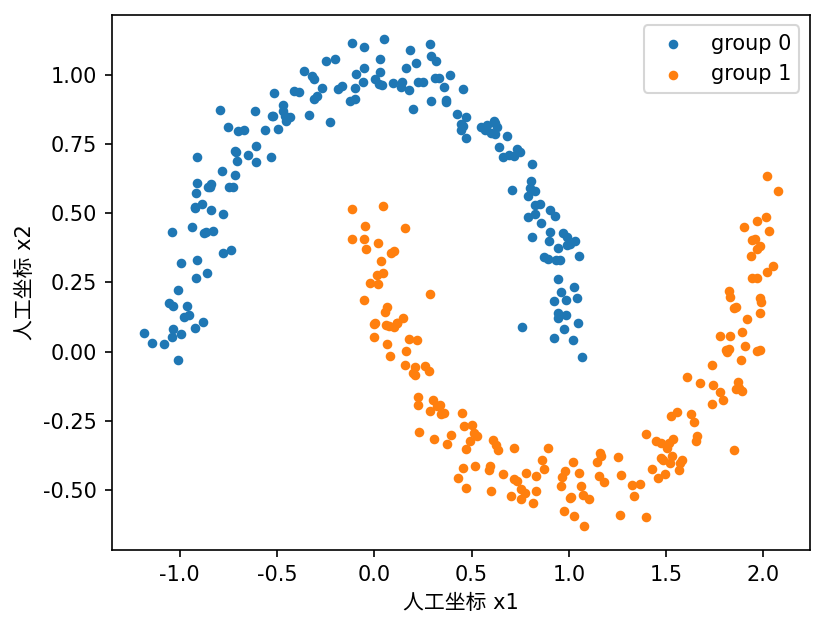

v3_ch14_K_means.png


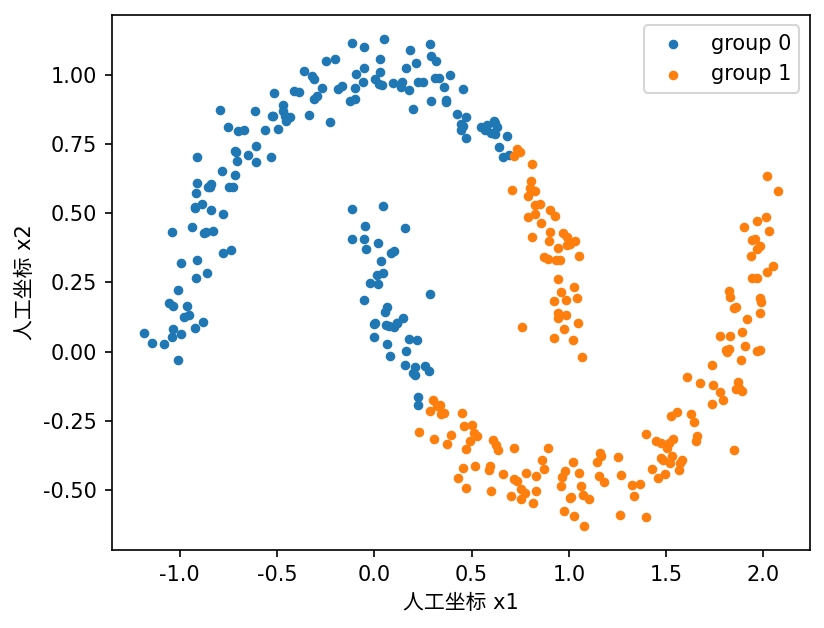

v3_ch14_single_link.png


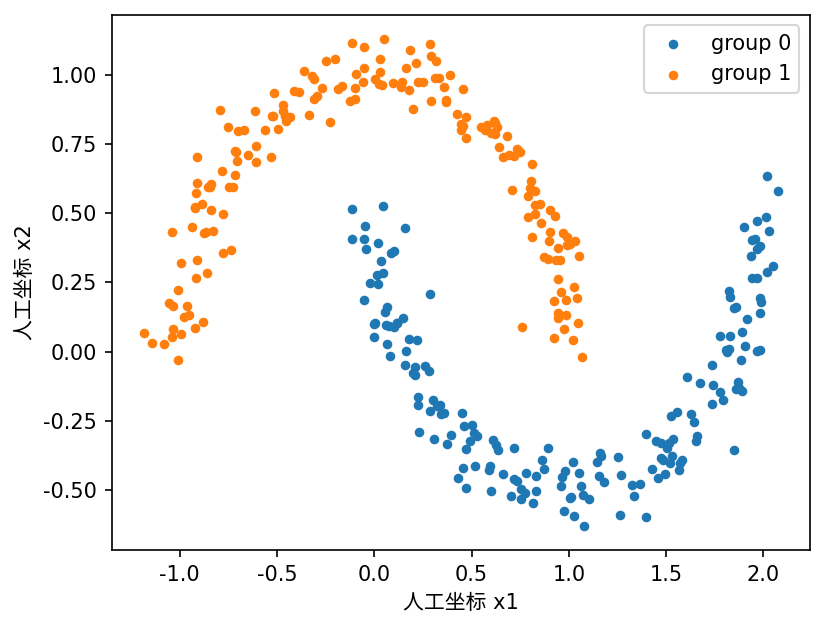

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch14_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 运行后的分析

解释一个与你的预判一致的结果，再解释一个需要进一步检查的现象。指出训练、验证和测试各使用哪些记录。

核对局部稳定解，比较K均值/层次/DBSCAN及不同指标。

**提交要求：**保存可顺序运行的Notebook、一个关键结果表、必要图形，以及150—300字的机制与限制解释。完成正文D题中与本实验相关的计算。不得仅提交最高分截图。